<a href="https://colab.research.google.com/github/sand02004/diabetes-readmission-ml/blob/main/readmission_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting 30-Day Hospital Readmission in Diabetic Patients
**Author:** Sandrine Umugwaneza, African Leadership University

**Goal:** Compare traditional ML and deep learning for classifying readmission (<30, >30, NO) using the UCI Diabetes 130-US Hospitals dataset (101,766 encounters).

**Data:** Strack et al. (2014), UCI ML Repository, DOI 10.24432/C5230J, licensed CC BY 4.0.

## 1. Setup
Install W&B (offline logging for the experiment table), import all libraries in one place, and fix random seeds for reproducibility.

In [109]:
!pip install -q wandb

import os, random, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
import wandb
from tensorflow import keras
from tensorflow.keras import layers
from wandb.integration.keras import WandbMetricsLogger

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, recall_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ["WANDB_MODE"] = "offline"   # required by the rubric
os.environ["WANDB_SILENT"] = "true"
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
print("TF:", tf.__version__)

TF: 2.21.0


In [ ]:
tf.config.experimental.enable_op_determinism()

## 2. Load the data
Mount Google Drive, then read `diabetic_data.csv`. Missing values are stored as `?`, so they are converted to NaN on load.

In [110]:
from google.colab import drive
drive.mount("/content/drive")


os.environ["WANDB_DIR"] = "/content/drive/MyDrive/summative"
os.makedirs(os.environ["WANDB_DIR"], exist_ok=True)

DATA_PATH = "/content/drive/MyDrive/summative/diabetic_data.csv"
print("Data file found:", os.path.exists(DATA_PATH))

df = pd.read_csv(DATA_PATH, na_values="?")
print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data file found: True


/tmp/ipykernel_2556/2067793053.py:7: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, na_values="?")


(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. First look at the data
Check class balance, missing values, and repeated patients. These checks decide the cleaning steps and the train/test split strategy.

In [111]:
print(df["readmitted"].value_counts(normalize=True).round(3))
print("\nMissing % (top columns):")
print((df.isna().mean() * 100).sort_values(ascending=False).head(10).round(1))
print("\nUnique patients:", df["patient_nbr"].nunique(), "of", len(df), "rows")
print("Duplicate encounter IDs:", df["encounter_id"].duplicated().sum())

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64

Missing % (top columns):
weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
patient_nbr           0.0
dtype: float64

Unique patients: 71518 of 101766 rows
Duplicate encounter IDs: 0


**Interpretation:** The target is imbalanced (NO 53.9%, >30 34.9%, <30 11.2%), so accuracy alone would be misleading and macro-F1 and per-class recall will be used. `weight` is 96.9% missing and will be dropped. `max_glu_serum` and `A1Cresult` are mostly missing because the test was not performed, which is itself informative. Only 71,518 unique patients appear in 101,766 encounters, so patients repeat and the split must be done by `patient_nbr` to prevent leakage. There are no duplicate encounters.

## 4. Target distribution
Visualise the three readmission classes to confirm the imbalance.

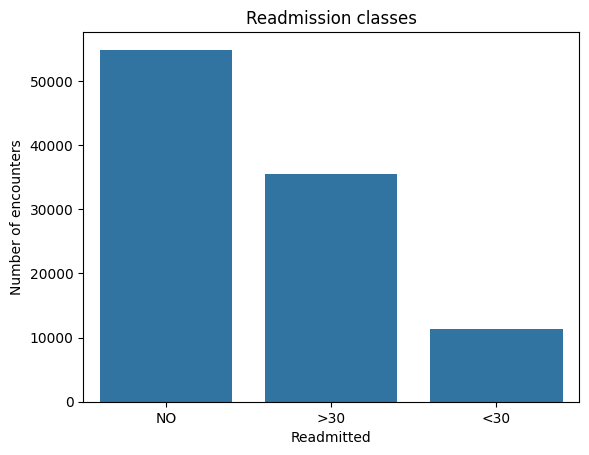

In [112]:
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"])
plt.title("Readmission classes"); plt.xlabel("Readmitted"); plt.ylabel("Number of encounters")
plt.show()

**Interpretation:** "NO" is the largest class (about 54%), followed by ">30" (35%) and "<30" (11%). A model that always predicts "NO" would score about 54% accuracy while detecting no early readmissions, so macro-F1, per-class recall and AUC are used alongside accuracy.

## 5. Data cleaning
- Drop `weight` (96.9% missing).
- Treat NaN in `max_glu_serum` and `A1Cresult` as "Not tested" (the test was not performed, which is informative).
- Fill the remaining missing categorical values with "Unknown".
- Remove patients who died or went to hospice (discharge IDs 11, 13, 14, 19, 20, 21), since they cannot be readmitted.
- Remove the rows with invalid gender.

In [113]:
df_clean = df.drop(columns=["weight"]).copy()

for c in ["max_glu_serum", "A1Cresult"]:
    df_clean[c] = df_clean[c].fillna("Not tested")

obj_cols = df_clean.select_dtypes("object").columns
df_clean[obj_cols] = df_clean[obj_cols].fillna("Unknown")

before = len(df_clean)
df_clean = df_clean[~df_clean["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"]
print(f"Rows removed: {before - len(df_clean)} | Remaining: {len(df_clean)}")

print("Remaining NaN:", df_clean.isna().sum().sum())
print(df_clean["readmitted"].value_counts(normalize=True).round(3))

Rows removed: 2426 | Remaining: 99340
Remaining NaN: 0
readmitted
NO     0.529
>30    0.357
<30    0.114
Name: proportion, dtype: float64


**Interpretation:** Cleaning removed 2,426 rows (2.4%): patients who died or entered hospice, plus invalid gender entries. No missing values remain. Class proportions barely changed (NO 52.9%, >30 35.7%, <30 11.4%), so the imbalance is a genuine property of the data and not an artefact of cleaning.

## 6. Exploratory analysis
Prior inpatient visits are expected to be a strong signal of readmission. The plot shows the share of each class by number of prior inpatient visits (capped at 5+).

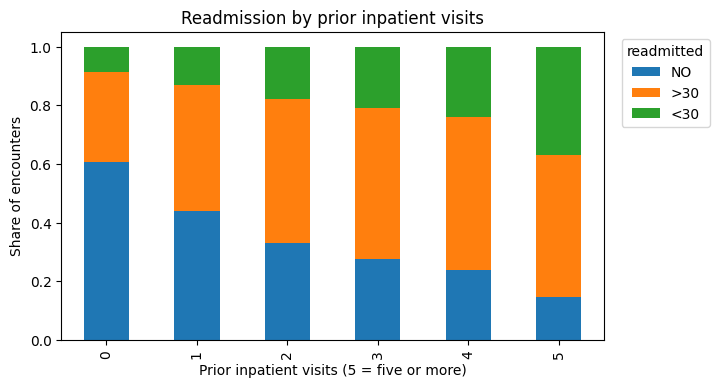

In [114]:
tmp = df_clean.copy()
tmp["prior_inpatient"] = tmp["number_inpatient"].clip(upper=5)
(pd.crosstab(tmp["prior_inpatient"], tmp["readmitted"], normalize="index")[["NO", ">30", "<30"]]
   .plot(kind="bar", stacked=True, figsize=(7, 4)))
plt.title("Readmission by prior inpatient visits")
plt.xlabel("Prior inpatient visits (5 = five or more)"); plt.ylabel("Share of encounters")
plt.legend(title="readmitted", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Interpretation:** The share of "NO" falls from about 61% for patients with no prior inpatient visits to about 15% for those with five or more, while the share of "<30" rises from roughly 9% to 37%. Prior inpatient utilisation is a strong, monotonic signal of readmission risk, which supports the combined `total_prior_visits` feature.

## 7. Feature engineering
- **age**: bracket converted to its midpoint (ordinal numeric).
- **diag_1, diag_2, diag_3**: ICD-9 codes grouped into 9 clinical categories (hundreds of raw codes would be too sparse).
- **total_prior_visits**: outpatient + emergency + inpatient visits in the prior year.
- **n_meds_used / n_med_changes**: number of medications prescribed and number whose dose was changed.
- **medical_specialty**: keep the 10 most common, group the rest as "Other".
- Drop constant columns and identifiers (patient ID is kept separately for splitting).
- Encode the target as NO = 0, >30 = 1, <30 = 2.

In [115]:
def icd9_group(code):
    if code == "Unknown": return "Unknown"
    if code[0] in "VE": return "Other"
    try: c = float(code)
    except ValueError: return "Other"
    if int(c) == 250: return "Diabetes"
    if 390 <= c <= 459 or int(c) == 785: return "Circulatory"
    if 460 <= c <= 519 or int(c) == 786: return "Respiratory"
    if 520 <= c <= 579 or int(c) == 787: return "Digestive"
    if 800 <= c <= 999: return "Injury"
    if 710 <= c <= 739: return "Musculoskeletal"
    if 580 <= c <= 629 or int(c) == 788: return "Genitourinary"
    if 140 <= c <= 239: return "Neoplasms"
    return "Other"

med_cols = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride",
            "acetohexamide","glipizide","glyburide","tolbutamide","pioglitazone",
            "rosiglitazone","acarbose","miglitol","troglitazone","tolazamide","examide",
            "citoglipton","insulin","glyburide-metformin","glipizide-metformin",
            "glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]

fe = df_clean.copy()

# age midpoint
fe["age"] = fe["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(float).mean(axis=1)

# diagnosis groups
for c in ["diag_1", "diag_2", "diag_3"]:
    fe[c] = fe[c].apply(icd9_group)

# utilisation and medication features
fe["total_prior_visits"] = fe["number_outpatient"] + fe["number_emergency"] + fe["number_inpatient"]
fe["n_meds_used"] = (fe[med_cols] != "No").sum(axis=1)
fe["n_med_changes"] = fe[med_cols].isin(["Up", "Down"]).sum(axis=1)

# rare specialties
top_spec = fe["medical_specialty"].value_counts().nlargest(10).index
fe["medical_specialty"] = fe["medical_specialty"].where(fe["medical_specialty"].isin(top_spec), "Other")

# drop constant columns and encounter id
const_cols = [c for c in fe.columns if fe[c].nunique() == 1]
print("Constant columns dropped:", const_cols)
fe = fe.drop(columns=const_cols + ["encounter_id"])

# target encoding, with a safety check
fe["target"] = fe["readmitted"].map({"NO": 0, ">30": 1, "<30": 2})
fe = fe.drop(columns="readmitted")
assert fe["target"].notna().all(), "Target has NaN: re-run Cell 5 (cleaning) first, then this cell"
fe["target"] = fe["target"].astype(int)
print(fe.shape, fe["target"].value_counts().to_dict())

Constant columns dropped: ['examide', 'citoglipton']
(99340, 49) {0: 52524, 1: 35502, 2: 11314}


**Interpretation:** Two medication columns (`examide`, `citoglipton`) contain a single value for every patient and carry no information, so they were dropped along with `encounter_id`. The dataset now has 49 columns, including `patient_nbr` (kept only for splitting) and the encoded target, with no missing target values.

## 8. Patient-level train / validation / test split
Patients appear in several encounters, so a random row split would leak information between sets. `GroupShuffleSplit` on `patient_nbr` keeps all of a patient's encounters in one set (70% / 15% / 15%).

In [116]:
groups = fe["patient_nbr"]

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(fe, groups=groups))
train, temp = fe.iloc[train_idx], fe.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(temp, groups=temp["patient_nbr"]))
val, test = temp.iloc[val_idx], temp.iloc[test_idx]

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, len(d), d["target"].value_counts(normalize=True).round(3).to_dict())

print("Patient overlap train/test:", len(set(train.patient_nbr) & set(test.patient_nbr)))
print("Patient overlap train/val:", len(set(train.patient_nbr) & set(val.patient_nbr)))

train 69613 {0: 0.528, 1: 0.358, 2: 0.114}
val 14868 {0: 0.53, 1: 0.355, 2: 0.116}
test 14859 {0: 0.531, 1: 0.356, 2: 0.113}
Patient overlap train/test: 0
Patient overlap train/val: 0


**Interpretation:** The patient-level split produced train (69,613), validation (14,868) and test (14,859) sets. Class proportions are almost identical across the three sets (about 53% NO, 36% >30, 11% <30), and no patient appears in more than one set, so evaluation is free of patient-level leakage.

## 9. Preprocessing pipeline
- Numeric features are standardised; categorical features are one-hot encoded (unseen categories ignored).
- The three ID columns (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) are codes, not quantities, so they are treated as categorical.
- The pipeline is **fitted on the training set only**, then applied to validation and test sets to avoid leakage.

In [117]:
ID_AS_CAT = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

def make_xy(d):
    X = d.drop(columns=["target", "patient_nbr"]).copy()
    X[ID_AS_CAT] = X[ID_AS_CAT].astype(str)
    return X, d["target"].values

X_train, y_train = make_xy(train)
X_val, y_val = make_xy(val)
X_test, y_test = make_xy(test)

cat_cols = X_train.select_dtypes("object").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

Xtr = preprocessor.fit_transform(X_train).astype("float32")
Xva = preprocessor.transform(X_val).astype("float32")
Xte = preprocessor.transform(X_test).astype("float32")
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))
print("Matrix shapes:", Xtr.shape, Xva.shape, Xte.shape)
print("NaN in matrices:", np.isnan(Xtr).sum(), np.isnan(Xva).sum(), np.isnan(Xte).sum())
print("NaN in targets:", np.isnan(y_train).sum(), np.isnan(y_val).sum(), np.isnan(y_test).sum())

Numeric: 12 | Categorical: 35
Matrix shapes: (69613, 201) (14868, 201) (14859, 201)
NaN in matrices: 0 0 0
NaN in targets: 0 0 0


**Interpretation:** The 12 numeric and 35 categorical features expand to 201 model inputs after one-hot encoding. The scaler and encoder were fitted on the training set only, and the train, validation and test matrices share the same width, with no missing values in the inputs or targets.

## 9b. Outlier check
Summary statistics of the numeric features show whether extreme values need handling. A maximum far above the median indicates a long right tail.

In [118]:
X_train[num_cols].describe().T[["mean", "50%", "max"]].round(1)

,mean,50%,max
age,65.7,65.0,95.0
time_in_hospital,4.4,4.0,14.0
num_lab_procedures,42.9,44.0,129.0
num_procedures,1.3,1.0,6.0
num_medications,16.0,15.0,81.0
number_outpatient,0.4,0.0,42.0
number_emergency,0.2,0.0,76.0
number_inpatient,0.6,0.0,21.0
number_diagnoses,7.4,8.0,16.0
total_prior_visits,1.2,0.0,80.0


**Interpretation:** Most numeric features are well behaved, with the mean close to the median (age 65.7 vs 65.0, time in hospital 4.4 vs 4.0, lab procedures 42.9 vs 44.0, diagnoses 7.4 vs 8.0). Prior-visit counts have heavy right tails: `number_outpatient`, `number_emergency` and `number_inpatient` have a median of 0 but maxima of 42, 76 and 21, and `num_medications` reaches 81 against a median of 15. These values are records of heavily treated patients, not data errors, so they were kept, and removing them would discard the highest-risk patients. Tree-based models are insensitive to extreme values, and the neural network receives standardised inputs. The extreme counts may still affect logistic regression and the MLP, which is noted as a limitation.

## Save processed data
Saves the preprocessed matrices and labels to Drive so the notebook can be resumed after a disconnect without re-running the pipeline.

In [119]:
SAVE_DIR = "/content/drive/MyDrive/summative"
os.makedirs(SAVE_DIR, exist_ok=True)
SAVE = os.path.join(SAVE_DIR, "processed.npz")
np.savez_compressed(SAVE, Xtr=Xtr, Xva=Xva, Xte=Xte, y_train=y_train, y_val=y_val, y_test=y_test)
print("Saved:", os.path.exists(SAVE), "|", round(os.path.getsize(SAVE) / 1e6, 1), "MB")

Saved: True | 4.0 MB


## 10. Evaluation helper
One function trains a model, logs the run to W&B (offline) and records its metrics, so every experiment is measured identically and collected for the experiment table. Metrics are computed on the validation set: accuracy, macro-F1, recall for the critical `<30` class, and one-vs-rest macro ROC-AUC.

In [120]:
results = []
SPLIT = "Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val"

def evaluate(exp_id, name, model, params, notes="", sample_weight=None):
    wandb.init(project="readmission-summative", name=exp_id, mode="offline", reinit=True,
               config={"model": name, "params": params, "split": SPLIT})
    start = time.time()
    if sample_weight is not None:
        model.fit(Xtr, y_train, sample_weight=sample_weight)
    else:
        model.fit(Xtr, y_train)
    secs = time.time() - start

    proba = model.predict_proba(Xva)
    pred = proba.argmax(axis=1)
    rec = recall_score(y_val, pred, average=None)
    row = {"Exp": exp_id, "Model": name, "Params": params, "Split": SPLIT,
           "Accuracy": round(accuracy_score(y_val, pred), 3),
           "Macro-F1": round(f1_score(y_val, pred, average="macro"), 3),
           "Recall <30": round(rec[2], 3),
           "AUC (OvR)": round(roc_auc_score(y_val, proba, multi_class="ovr", average="macro"), 3),
           "Time (s)": round(secs, 1), "Notes": notes}
    wandb.log({k: row[k] for k in ["Accuracy", "Macro-F1", "Recall <30", "AUC (OvR)", "Time (s)"]})
    wandb.finish()
    results.append(row)
    return pd.DataFrame([row]).drop(columns=["Params", "Split", "Notes"])

## 11. Baseline traditional models
- **E1:** Logistic Regression, no class weighting (baseline).
- **E2:** Logistic Regression with balanced class weights (tests the effect of imbalance handling).
- **E3:** Random Forest with balanced class weights (non-linear, handles interactions).
- **E4:** Histogram Gradient Boosting with balanced sample weights (strong boosting method).

SVM is omitted as the kernel version scales poorly to about 70,000 rows with 200+ features; this trade-off is noted in the report.

In [121]:
sw = compute_sample_weight("balanced", y_train)

evaluate("E1", "Logistic Regression",
    LogisticRegression(max_iter=1000, random_state=SEED),
    "C=1, no class weight", "Highest accuracy but misses 97% of <30 cases")

evaluate("E2", "Logistic Regression",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "C=1, class_weight=balanced", "Balanced weights raised <30 recall from 0.03 to 0.40; accuracy fell")

evaluate("E3", "Random Forest",
    RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED),
    "200 trees, depth 12, balanced_subsample", "Non-linear model; similar macro-F1 to boosting")

evaluate("E4", "HistGradientBoosting",
    HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED),
    "200 iters, lr 0.1, balanced sample weights", "Best baseline macro-F1 and AUC", sample_weight=sw)

pd.DataFrame(results).drop(columns=["Params", "Split", "Notes"])

,Exp,Model,Accuracy,Macro-F1,Recall <30,AUC (OvR),Time (s)
0,E1,Logistic Regression,0.570,0.378,0.026,0.660,67.1
1,E2,Logistic Regression,0.500,0.440,0.400,0.656,70.3
2,E3,Random Forest,0.521,0.442,0.325,0.662,28.1
3,E4,HistGradientBoosting,0.506,0.448,0.399,0.667,22.9


**Interpretation:** E1 has the highest accuracy (0.570) but is misleading: it detects only 2.6% of `<30` readmissions (macro-F1 0.378), because it mostly predicts the majority class. Balanced class weights (E2) trade accuracy (0.500) for much better minority recall (0.400) and macro-F1 (0.440), while AUC is essentially unchanged (0.660 vs 0.656). This shows weighting shifts the decision boundary rather than improving the model's ability to rank patients. Random Forest (E3) and Gradient Boosting (E4) are similar, and E4 is best overall (macro-F1 0.448, AUC 0.667). That all models cluster around AUC 0.66-0.67 suggests limited signal in the features (high bias and irreducible noise) rather than a model-choice problem, consistent with readmission being hard to predict in published work.

## 12. tf.data input pipeline
The preprocessed matrices are wrapped in `tf.data.Dataset` objects with shuffling (training only), batching and prefetching, as required for the deep learning pipeline.

In [122]:
def make_ds(X, y, shuffle=False, batch=512):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(Xtr, y_train, shuffle=True)
val_ds = make_ds(Xva, y_val)
test_ds = make_ds(Xte, y_test)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 201), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


**Interpretation:** The training data is shuffled with a fixed seed, batched in groups of 512 encoded patients (201 features each) and prefetched, so the network reads data through an efficient `tf.data` pipeline. Validation and test sets are batched without shuffling.

## 13. Model builder and training helper
A Sequential MLP with configurable layer sizes, dropout, L2 regularisation and learning rate. Training uses class weights (to match the ML experiments), early stopping on validation loss, and offline W&B logging. Each run's history is stored for learning curves.

In [123]:
cw_arr = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weights = {i: w for i, w in enumerate(cw_arr)}
histories = {}

def build_mlp(input_dim, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3):
    reg = keras.regularizers.l2(l2)
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(3, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def run_dl(exp_id, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3, epochs=40, notes=""):
    keras.utils.set_random_seed(SEED)
    cfg = dict(units=units, dropout=dropout, l2=l2, lr=lr, epochs=epochs)
    wandb.init(project="readmission-summative", name=exp_id, config=cfg, mode="offline", reinit=True)
    model = build_mlp(Xtr.shape[1], units, dropout, l2, lr)
    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=class_weights, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                                WandbMetricsLogger()])
    secs = time.time() - start
    wandb.finish()
    histories[exp_id] = hist.history

    proba = model.predict(Xva, batch_size=1024, verbose=0)
    pred = proba.argmax(axis=1)
    rec = recall_score(y_val, pred, average=None)
    row = {"Exp": exp_id, "Model": "Keras MLP", "Params": str(cfg), "Split": SPLIT,
           "Accuracy": round(accuracy_score(y_val, pred), 3),
           "Macro-F1": round(f1_score(y_val, pred, average="macro"), 3),
           "Recall <30": round(rec[2], 3),
           "AUC (OvR)": round(roc_auc_score(y_val, proba, multi_class="ovr", average="macro"), 3),
           "Time (s)": round(secs, 1), "Notes": notes}
    results.append(row)
    print(f"{exp_id}: stopped after {len(hist.history['loss'])} epochs")
    return model, pd.DataFrame([row]).drop(columns=["Params", "Split", "Notes"])

## 14. First deep learning experiments
- **E5:** MLP (128-64), dropout 0.3, class-weighted loss (baseline neural network).
- **E6:** Wider and deeper MLP (256-128-64) with stronger dropout 0.4 to test whether more capacity helps.

In [124]:
print("Experiments recorded so far:", len(results), "(expected 4: E1 to E4)")

model_e5, r5 = run_dl("E5", units=(128, 64), dropout=0.3,
                      notes="Baseline MLP; matches boosting AUC but lower macro-F1")
model_e6, r6 = run_dl("E6", units=(256, 128, 64), dropout=0.4,
                      notes="More capacity gave no gain over E5")
pd.concat([r5, r6])

Experiments recorded so far: 4 (expected 4: E1 to E4)
E5: stopped after 19 epochs
E6: stopped after 16 epochs


,Exp,Model,Accuracy,Macro-F1,Recall <30,AUC (OvR),Time (s)
0,E5,Keras MLP,0.525,0.423,0.366,0.667,39.9
0,E6,Keras MLP,0.536,0.410,0.335,0.666,44.6


**Interpretation:** The baseline MLP (E5) reached accuracy 0.525, macro-F1 0.423 and AUC 0.667, matching the best traditional model's AUC (E4: 0.667) but with lower macro-F1 (0.448). The wider and deeper network (E6) did not help: accuracy rose slightly (0.536), but macro-F1 (0.410) and `<30` recall (0.335) fell, with an almost identical AUC (0.666). Extra capacity added no ranking power, which suggests the limit is the information in the features rather than model complexity.

## 15. Learning curves (E5 vs E6)
Training and validation loss per epoch, used to diagnose over- and underfitting.

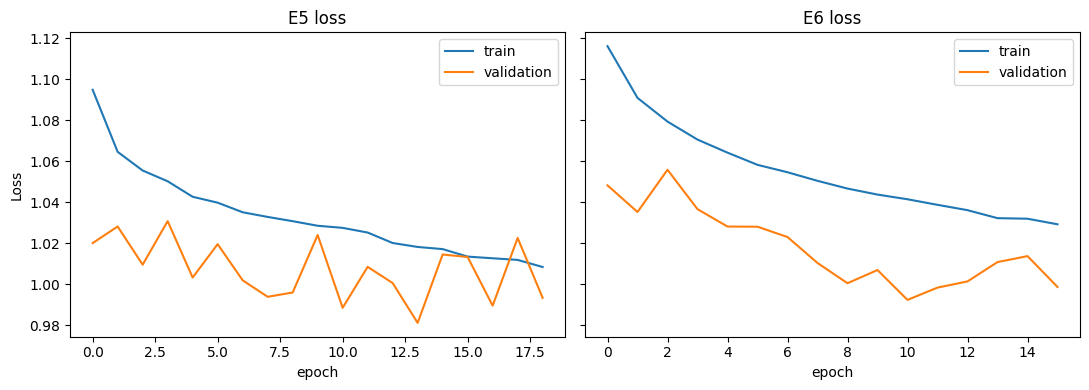

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, eid in zip(axes, ["E5", "E6"]):
    h = histories[eid]
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validation")
    ax.set_title(f"{eid} loss"); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("Loss")
plt.tight_layout(); plt.show()

**Interpretation:** Training loss falls smoothly in both runs (E5: about 1.10 to 1.01; E6: about 1.12 to 1.03), while validation loss stays flat at roughly 0.98-1.03 and swings from epoch to epoch. The curves do not diverge, so there is no clear overfitting. Early stopping (patience 5) halted training after 19 epochs for E5 and 16 for E6, and restored the weights from the best validation epoch (about epoch 14 for E5 and epoch 11 for E6). Validation loss sits below training loss because dropout, the L2 penalty and the class weights act only on the training loss. The plateau and the small gap indicate high bias (limited signal in the features) rather than high variance. E6's lower training loss with no validation gain confirms that added capacity does not help.

## 16. Tuning experiments
The curves suggest high bias and limited signal, so the next experiments test regularisation and learning rate rather than more capacity.
- **E7:** Gradient Boosting, shallow and regularised (depth 4, lr 0.05, L2 = 1.0).
- **E8:** Gradient Boosting, deeper trees (63 leaves, min 50 samples per leaf, lr 0.05).
- **E9:** Smaller MLP (64-32), lower dropout (0.2), lower learning rate (5e-4).

In [126]:
print("Experiments recorded so far:", len(results), "(expected 6: E1 to E6)")

evaluate("E7", "HistGradientBoosting",
    HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=400,
        l2_regularization=1.0, early_stopping=True, random_state=SEED),
    "depth 4, lr 0.05, L2 1.0, early stopping",
    "Shallow, regularised trees gave no gain over E4", sample_weight=sw)

evaluate("E8", "HistGradientBoosting",
    HistGradientBoostingClassifier(max_leaf_nodes=63, min_samples_leaf=50, learning_rate=0.05,
        max_iter=400, early_stopping=True, random_state=SEED),
    "63 leaves, min leaf 50, lr 0.05, early stopping",
    "Deeper trees with min leaf size gave the best validation macro-F1 before tuning", sample_weight=sw)

model_e9, r9 = run_dl("E9", units=(64, 32), dropout=0.2, lr=5e-4, epochs=60,
                      notes="Smaller network, lower learning rate")

pd.DataFrame(results[-3:]).drop(columns=["Params", "Split", "Notes"])

Experiments recorded so far: 6 (expected 6: E1 to E6)
E9: stopped after 15 epochs


,Exp,Model,Accuracy,Macro-F1,Recall <30,AUC (OvR),Time (s)
0,E7,HistGradientBoosting,0.503,0.445,0.413,0.666,49.8
1,E8,HistGradientBoosting,0.510,0.451,0.400,0.667,41.0
2,E9,Keras MLP,0.514,0.396,0.418,0.662,36.1


**Interpretation:** Regularising Gradient Boosting (E7: depth 4, L2 = 1.0) gave no gain over the default E4 (macro-F1 0.445 vs 0.448). Allowing deeper trees with a minimum leaf size (E8) gave the best macro-F1 so far (0.451) with AUC 0.667, equal to E4, so tree complexity changes the result only marginally. The smaller, lower-learning-rate MLP (E9) reached the highest `<30` recall (0.418) but the lowest macro-F1 (0.396) and AUC (0.662): it flags more patients as `<30` at the cost of many false alarms (lower precision). Across nine experiments, AUC stays within 0.656-0.667, which indicates a performance ceiling set by the information in the features (high bias and noise), not by tuning. This motivates adjusting the decision threshold rather than the model.

## 17. Threshold tuning (E10)
All models share an AUC ceiling, so the remaining lever is the decision rule. The best traditional model (E8) is refitted and its predicted probabilities are rescaled per class. The two scaling factors are chosen on the **validation set** to maximise macro-F1. AUC is unchanged by rescaling, so this tests the precision/recall trade-off, not ranking quality.

In [127]:
best_ml = HistGradientBoostingClassifier(max_leaf_nodes=63, min_samples_leaf=50,
    learning_rate=0.05, max_iter=400, early_stopping=True, random_state=SEED)

start = time.time()
best_ml.fit(Xtr, y_train, sample_weight=sw)
secs = time.time() - start
proba_va = best_ml.predict_proba(Xva)

# search the two class scalings (>30, <30) that maximise macro-F1 on VALIDATION
best_f1, best_w = 0, None
for w1 in np.arange(0.6, 1.6, 0.1):
    for w2 in np.arange(0.6, 2.6, 0.1):
        pred = (proba_va * np.array([1, w1, w2])).argmax(axis=1)
        f1 = f1_score(y_val, pred, average="macro")
        if f1 > best_f1:
            best_f1, best_w = f1, (round(float(w1), 1), round(float(w2), 1))

W = np.array([1, *best_w])
pred = (proba_va * W).argmax(axis=1)
rec = recall_score(y_val, pred, average=None)

row = {"Exp": "E10", "Model": "HistGradientBoosting + threshold",
       "Params": f"E8 settings, class scaling (>30 x{best_w[0]}, <30 x{best_w[1]})",
       "Split": SPLIT,
       "Accuracy": round(accuracy_score(y_val, pred), 3),
       "Macro-F1": round(f1_score(y_val, pred, average="macro"), 3),
       "Recall <30": round(rec[2], 3),
       "AUC (OvR)": round(roc_auc_score(y_val, proba_va, multi_class="ovr", average="macro"), 3),
       "Time (s)": round(secs, 1),
       "Notes": "Rescaling raised macro-F1 but cut <30 recall; AUC unchanged"}
results.append(row)

wandb.init(project="readmission-summative", name="E10", mode="offline", reinit=True,
           config={"base": "E8 settings", "scaling_gt30": best_w[0], "scaling_lt30": best_w[1]})
wandb.log({k: row[k] for k in ["Accuracy", "Macro-F1", "Recall <30", "AUC (OvR)"]})
wandb.finish()

print("Best scaling:", best_w)
pd.DataFrame([row]).drop(columns=["Params", "Split", "Notes"])

Best scaling: (0.9, 0.7)


,Exp,Model,Accuracy,Macro-F1,Recall <30,AUC (OvR),Time (s)
0,E10,HistGradientBoosting + threshold,0.558,0.468,0.237,0.667,44.8


**Interpretation:** Rescaling the predicted probabilities (>30 × 0.9, <30 × 0.7) gave the best macro-F1 of all experiments (0.468) and raised accuracy to 0.558, while AUC stayed at 0.667 because rescaling changes the decision rule, not the ranking. The scaling factors below 1 show that the balanced sample weights used in training had pushed the model to over-predict the minority classes, and the threshold step corrected part of that. The cost is `<30` recall, which fell from 0.400 (E8) to 0.237. This is a precision/recall trade-off: E10 maximises overall balance, while a hospital that prioritises catching early readmissions would choose a threshold closer to E8 or E9, accepting more false alarms. The scaling factors were tuned on the validation set, so final performance must be reported on the untouched test set.

## 17a. Learning curve: Gradient Boosting (E8 settings)
Training and validation macro-F1 for growing training-set sizes, to diagnose over- and underfitting in the tree model.

Experiments recorded so far: 10 (expected 10: E1 to E10)


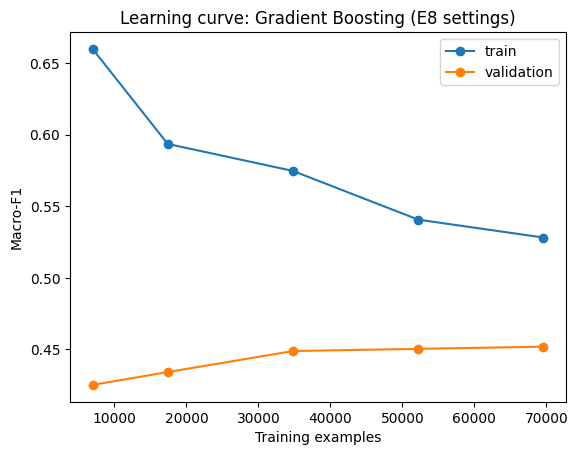

[0.66, 0.594, 0.575, 0.541, 0.528]
[0.425, 0.434, 0.449, 0.45, 0.452]


In [128]:
print("Experiments recorded so far:", len(results), "(expected 10: E1 to E10)")

fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
sizes, tr_f1, va_f1 = [], [], []
order = np.random.RandomState(SEED).permutation(len(Xtr))
for f in fracs:
    ii = order[:int(f * len(Xtr))]
    m = HistGradientBoostingClassifier(max_leaf_nodes=63, min_samples_leaf=50, learning_rate=0.05,
            max_iter=400, early_stopping=True, random_state=SEED)
    m.fit(Xtr[ii], y_train[ii], sample_weight=sw[ii])
    sizes.append(len(ii))
    tr_f1.append(f1_score(y_train[ii], m.predict(Xtr[ii]), average="macro"))
    va_f1.append(f1_score(y_val, m.predict(Xva), average="macro"))

plt.plot(sizes, tr_f1, "o-", label="train")
plt.plot(sizes, va_f1, "o-", label="validation")
plt.xlabel("Training examples"); plt.ylabel("Macro-F1"); plt.legend()
plt.title("Learning curve: Gradient Boosting (E8 settings)"); plt.show()
print([round(x, 3) for x in tr_f1]); print([round(x, 3) for x in va_f1])

**Interpretation:** With only about 7,000 training examples, the model fits the training data well (macro-F1 0.660) but generalises poorly (validation 0.425), a gap of 0.235 that signals overfitting to a small sample. As the training set grows, training macro-F1 falls (to 0.528) and validation macro-F1 rises (to 0.452), so the gap narrows to 0.076. Validation performance flattens beyond about 35,000 examples (0.449, 0.450, 0.452), which means that more data of the same kind is unlikely to improve the model much. The remaining gap indicates mild variance, controlled by early stopping and the minimum leaf size, while the low plateau of the validation score indicates high bias: the features carry limited information about readmission. Gains would therefore need richer features, not more patients.

## 17b. Feature analysis: ablation (E11) and permutation importance
**E11** retrains the E8 model without the three engineered features (`total_prior_visits`, `n_meds_used`, `n_med_changes`) to test whether they add value. Permutation importance then shows which inputs the best model relies on most.

Experiments recorded so far: 10 (expected 10: E1 to E10)
   Exp  Accuracy  Macro-F1  Recall <30  AUC (OvR)
0  E11     0.508     0.448       0.388      0.665


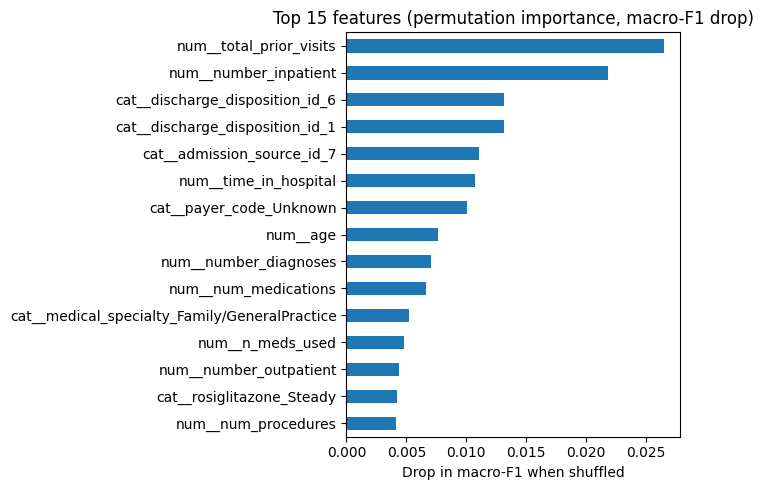

In [129]:
print("Experiments recorded so far:", len(results), "(expected 10: E1 to E10)")

# E11: ablation (numeric columns come first in the matrix, in num_cols order)
eng = ["total_prior_visits", "n_meds_used", "n_med_changes"]
keep = [i for i in range(Xtr.shape[1]) if not (i < len(num_cols) and num_cols[i] in eng)]

wandb.init(project="readmission-summative", name="E11", mode="offline", reinit=True,
           config={"base": "E8 settings", "removed": eng})
abl = HistGradientBoostingClassifier(max_leaf_nodes=63, min_samples_leaf=50, learning_rate=0.05,
        max_iter=400, early_stopping=True, random_state=SEED)
start = time.time()
abl.fit(Xtr[:, keep], y_train, sample_weight=sw)
secs = time.time() - start
proba = abl.predict_proba(Xva[:, keep]); pred = proba.argmax(axis=1)
rec = recall_score(y_val, pred, average=None)
row = {"Exp": "E11", "Model": "HistGradientBoosting (no engineered features)",
       "Params": "E8 settings, 3 engineered features removed", "Split": SPLIT,
       "Accuracy": round(accuracy_score(y_val, pred), 3),
       "Macro-F1": round(f1_score(y_val, pred, average="macro"), 3),
       "Recall <30": round(rec[2], 3),
       "AUC (OvR)": round(roc_auc_score(y_val, proba, multi_class="ovr", average="macro"), 3),
       "Time (s)": round(secs, 1),
       "Notes": "Ablation: removing the 3 engineered features lowered macro-F1 only slightly"}
results.append(row)
wandb.log({k: row[k] for k in ["Accuracy", "Macro-F1", "Recall <30", "AUC (OvR)"]})
wandb.finish()
print(pd.DataFrame([row])[["Exp", "Accuracy", "Macro-F1", "Recall <30", "AUC (OvR)"]])

# permutation importance of the E10 model (3,000 validation rows for speed)
idx = np.random.RandomState(SEED).choice(len(Xva), 3000, replace=False)
imp = permutation_importance(best_ml, Xva[idx], y_val[idx], scoring="f1_macro",
                             n_repeats=3, random_state=SEED, n_jobs=-1)
top = pd.Series(imp.importances_mean, index=preprocessor.get_feature_names_out()).sort_values().tail(15)
top.plot(kind="barh", figsize=(7, 5), title="Top 15 features (permutation importance, macro-F1 drop)")
plt.xlabel("Drop in macro-F1 when shuffled"); plt.tight_layout(); plt.show()

**Interpretation (E11 and feature importance):** Removing the three engineered features (E11) lowered macro-F1 only from 0.451 to 0.448, `<30` recall from 0.400 to 0.388 and AUC from 0.667 to 0.665. The engineered features therefore add a small gain, not a large one, because the original columns they summarise (`number_inpatient`, `number_outpatient`, `number_emergency` and the individual medication columns) remain in the data and carry most of the same information. Permutation importance on the final model shows that prior utilisation dominates: `total_prior_visits` and `number_inpatient` cause the largest macro-F1 drop when shuffled, followed by discharge disposition, admission source, time in hospital, payer code and age. This matches the exploratory plot, where readmission rose steadily with prior inpatient visits. `n_meds_used` also appears in the top 15, so the medication-count feature is useful. The importance of the "Unknown" payer category suggests that missing insurance information is itself informative, and it may proxy for patient circumstances. Importances were computed on a 3,000-row validation sample with three repeats and are approximate, and correlated features such as `total_prior_visits` and `number_inpatient` share importance between them.

## 18. Experiment table
All eleven experiments with their settings, data splits, validation metrics and notes. The same runs are logged in W&B offline mode.

In [130]:
exp_table = pd.DataFrame(results)
assert exp_table["Exp"].is_unique and len(exp_table) == 11, f"Expected 11 unique experiments, found {len(exp_table)}"
exp_table.to_csv("/content/drive/MyDrive/summative/experiment_table.csv", index=False)
exp_table

,Exp,Model,Params,Split,Accuracy,Macro-F1,Recall <30,AUC (OvR),Time (s),Notes
0,E1,Logistic Regression,"C=1, no class weight","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.570,0.378,0.026,0.660,67.1,Highest accuracy but misses 97% of <30 cases
1,E2,Logistic Regression,"C=1, class_weight=balanced","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.500,0.440,0.400,0.656,70.3,Balanced weights raised <30 recall from 0.03 to 0.40; accuracy fell
2,E3,Random Forest,"200 trees, depth 12, balanced_subsample","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.521,0.442,0.325,0.662,28.1,Non-linear model; similar macro-F1 to boosting
3,E4,HistGradientBoosting,"200 iters, lr 0.1, balanced sample weights","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.506,0.448,0.399,0.667,22.9,Best baseline macro-F1 and AUC
4,E5,Keras MLP,"{'units': (128, 64), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001, 'epochs': 40}","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.525,0.423,0.366,0.667,39.9,Baseline MLP; matches boosting AUC but lower macro-F1
5,E6,Keras MLP,"{'units': (256, 128, 64), 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.001, 'epochs...","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.536,0.410,0.335,0.666,44.6,More capacity gave no gain over E5
6,E7,HistGradientBoosting,"depth 4, lr 0.05, L2 1.0, early stopping","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.503,0.445,0.413,0.666,49.8,"Shallow, regularised trees gave no gain over E4"
7,E8,HistGradientBoosting,"63 leaves, min leaf 50, lr 0.05, early stopping","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.510,0.451,0.400,0.667,41.0,Deeper trees with min leaf size gave the best validation macro-F1 before tuning
8,E9,Keras MLP,"{'units': (64, 32), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.0005, 'epochs': 60}","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.514,0.396,0.418,0.662,36.1,"Smaller network, lower learning rate"
9,E10,HistGradientBoosting + threshold,"E8 settings, class scaling (>30 x0.9, <30 x0.7)","Train 69,613 / Val 14,868 / Test 14,859 (patient-level); metrics on Val",0.558,0.468,0.237,0.667,44.8,Rescaling raised macro-F1 but cut <30 recall; AUC unchanged


**Interpretation:** Across eleven experiments, AUC stays within 0.656-0.667 regardless of model family, so the features limit ranking quality more than model choice does. Class weighting (E1 to E2) and threshold rescaling (E8 to E10) mainly move the precision/recall balance, not the ranking. Gradient boosting (E4, E7, E8: macro-F1 0.445-0.451) matches or beats the neural networks (E5, E6, E9: 0.396-0.423), so for this tabular data deep learning brings no benefit. E10 gives the best macro-F1 (0.468) but the lowest `<30` recall (0.237), while E9 gives the highest recall (0.418) at the lowest macro-F1 (0.396). The ablation (E11) shows that removing the three engineered features lowers macro-F1 only slightly (0.451 to 0.448). The preferred model depends on whether the hospital values overall balance or catching early readmissions.

## 19. Final test-set evaluation
The selected models are evaluated once on the held-out test set: E10 (Gradient Boosting with tuned class scaling, the best traditional model) and E5 (Keras MLP, the best neural network by validation macro-F1). Reported: classification report, confusion matrices (row-normalised) and one-vs-rest macro AUC.

=== E10 Gradient Boosting ===
              precision    recall  f1-score   support

          NO      0.650     0.687     0.668      7884
         >30      0.489     0.467     0.478      5294
         <30      0.276     0.240     0.257      1681

    accuracy                          0.558     14859
   macro avg      0.472     0.465     0.468     14859
weighted avg      0.550     0.558     0.554     14859

Macro AUC (OvR): 0.674 

=== E5 Keras MLP ===
              precision    recall  f1-score   support

          NO      0.631     0.770     0.694      7884
         >30      0.512     0.219     0.307      5294
         <30      0.220     0.389     0.281      1681

    accuracy                          0.531     14859
   macro avg      0.454     0.459     0.427     14859
weighted avg      0.542     0.531     0.509     14859

Macro AUC (OvR): 0.674 



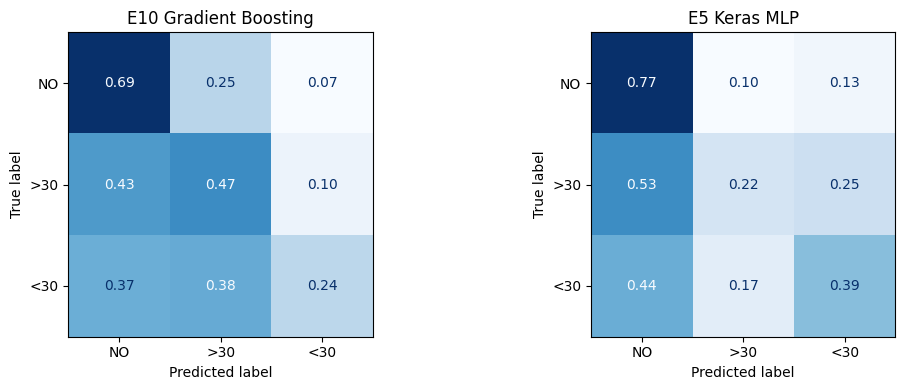

In [131]:
assert all(v in globals() for v in ["best_ml", "W", "model_e5"]), "Run the E10 cell and the E5 cell first"

names = ["NO", ">30", "<30"]
proba_ml = best_ml.predict_proba(Xte) * W
proba_dl = model_e5.predict(Xte, batch_size=1024, verbose=0)
models = {"E10 Gradient Boosting": proba_ml, "E5 Keras MLP": proba_dl}

for n, p in models.items():
    pred = p.argmax(axis=1)
    print(f"=== {n} ===")
    print(classification_report(y_test, pred, target_names=names, digits=3))
    print("Macro AUC (OvR):", round(roc_auc_score(y_test, p / p.sum(axis=1, keepdims=True), multi_class="ovr", average="macro"), 3), "\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (n, p) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, p.argmax(axis=1), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()

**Interpretation (E10, test set):** E10 reached accuracy 0.558, macro-F1 0.468 and macro AUC 0.674. Its test macro-F1 equals its validation score (0.468), so the scaling tuned on validation data generalised to unseen patients. The model is best on "NO" (F1 0.668) and weakest on "<30" (F1 0.257). It recovers 69% of "NO" cases and 47% of ">30" cases, but only 24% of "<30" cases. For "<30" patients, the errors are split between being predicted as "NO" (37%) and ">30" (38%), and being predicted as "NO" is the costly mistake clinically. Its `<30` precision (0.276) is about 2.4 times the 11% base rate, so it carries real signal, but three out of four early readmissions are still missed. The ">30" and "<30" classes overlap because they differ only in time since discharge, not in patient characteristics, so the features cannot separate them cleanly.

**Interpretation (E5 and comparison):** On the test set, the Keras MLP (E5) reached accuracy 0.531, macro-F1 0.427 and macro AUC 0.674, the same AUC as E10. E5 is strongest on "NO" (recall 0.770, F1 0.694) and weakest on ">30" (recall 0.219, F1 0.307), sending 53% of ">30" patients to "NO". For the critical "<30" class, E5 detects far more early readmissions than E10 (recall 0.389 vs 0.240), but with lower precision (0.220 vs 0.276), so most of its "<30" alerts are false alarms. Its "<30" F1 (0.281) is slightly higher than E10's (0.257), while E10 is better balanced overall (macro-F1 0.468 vs 0.427, accuracy 0.558 vs 0.531). For "<30" patients, E10 splits its errors almost evenly between "NO" (37%) and ">30" (38%), while E5 sends 44% of them to "NO", which is the costly mistake clinically. The two models therefore sit at different operating points: E10 is the more balanced classifier, and E5 is more sensitive to early readmission.

## 20. ROC curves
One-vs-rest ROC curve for each readmission class, for both final models.

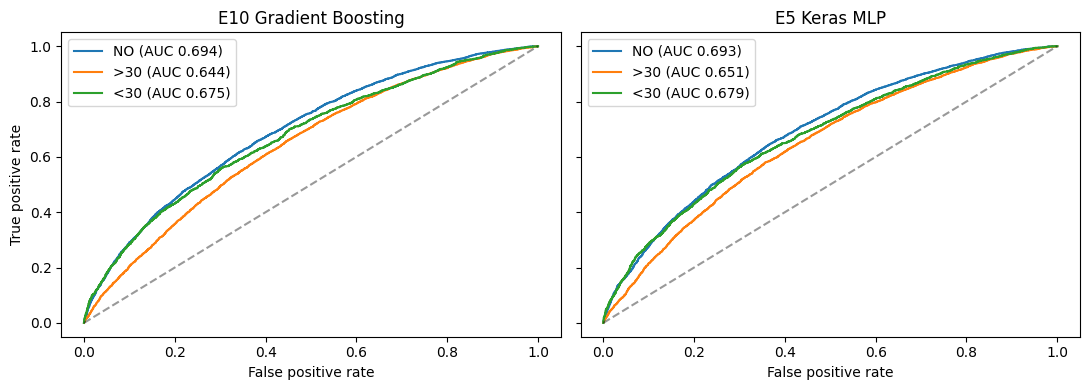

In [132]:
Y = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (n, p) in zip(axes, models.items()):
    for i, cname in enumerate(names):
        fpr, tpr, _ = roc_curve(Y[:, i], p[:, i])
        ax.plot(fpr, tpr, label=f"{cname} (AUC {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(n); ax.set_xlabel("False positive rate"); ax.legend()
axes[0].set_ylabel("True positive rate")
plt.tight_layout(); plt.show()

**Interpretation:** Both models reach almost identical one-vs-rest AUCs (E10: NO 0.694, >30 0.644, <30 0.675; E5: NO 0.693, >30 0.651, <30 0.679), well above chance (0.5) but far from strong discrimination. The ">30" class has the lowest AUC in both models, consistent with it being an intermediate class that resembles both its neighbours. The curves nearly overlap, so the difference between the models in the confusion matrices comes from where each one places its decision threshold, not from better ranking ability. This supports the conclusion that the ceiling comes from the information in the features, not from model choice.

**Bias-variance analysis:** Test scores are as good as validation scores (E10 macro-F1 0.468 on both; macro AUC about 0.667 on validation and 0.674 on test), and the learning curves show no divergence for the neural network and a narrow, shrinking gap for gradient boosting, so variance is low. The consistently modest AUC across logistic regression, tree ensembles and neural networks points to high bias and irreducible noise, since readmission depends on factors absent from the data, such as social support, medication adherence and post-discharge care.

## 21. Save best models
The best traditional model (E10, with its class scaling and preprocessor) is saved with joblib, and the best deep learning model (E5) in Keras format, for the Google Drive deliverable.

In [133]:
joblib.dump({"model": best_ml, "class_scaling": W, "preprocessor": preprocessor},
            "/content/drive/MyDrive/summative/best_ml_model.joblib")
model_e5.save("/content/drive/MyDrive/summative/best_dl_model.keras")
print("Models saved:", os.path.exists("/content/drive/MyDrive/summative/best_ml_model.joblib"),
      os.path.exists("/content/drive/MyDrive/summative/best_dl_model.keras"))

Models saved: True True


## 22. Archive experiment logs
The offline W&B logs for all experiments are zipped to Drive, so the experiment table can be traced back to the logged runs.

In [135]:
from datetime import datetime

cands = {p: sorted(d for d in os.listdir(p) if d.startswith("offline-run"))
         for p in ["/content/wandb", "/content/drive/MyDrive/summative/wandb"] if os.path.isdir(p)}
wb = max(cands, key=lambda p: cands[p][-1] if cands[p] else "")
last11 = cands[wb][-11:]
ts = [datetime.strptime(d.split("-")[2], "%Y%m%d_%H%M%S") for d in last11]

print("Folder:", wb, "| total runs found:", len(cands[wb]))
print("First of final 11:", last11[0], "->", ts[0])
print("Last of final 11: ", last11[-1], "->", ts[-1])
print("Span (minutes):", round((ts[-1] - ts[0]).total_seconds() / 60, 1))
assert (ts[-1] - ts[0]).total_seconds() < 90 * 60, "The last 11 runs are too far apart: send me the lines above"

clean = "/content/wandb_final"
shutil.rmtree(clean, ignore_errors=True); os.makedirs(clean)
for d in last11:
    shutil.copytree(os.path.join(wb, d), os.path.join(clean, d))
shutil.make_archive("/content/drive/MyDrive/summative/wandb_logs", "zip", clean)
print("Zipped final 11 runs:", os.path.exists("/content/drive/MyDrive/summative/wandb_logs.zip"))

Folder: /content/wandb | total runs found: 36
First of final 11: offline-run-20261015_084011-uhir85zu -> 2026-10-15 08:40:11
Last of final 11:  offline-run-20261015_085058-bhj68ewj -> 2026-10-15 08:50:58
Span (minutes): 10.8
Zipped final 11 runs: True


## Conclusions
- **Best model:** Gradient Boosting with tuned class scaling (E10) gave the best test macro-F1 (0.468) and accuracy (0.558). The Keras MLP (E5) detected more `<30` cases (recall 0.39 vs 0.24) but with more false alarms.
- **Main finding:** All model families reach a similar AUC (about 0.67), so the features limit performance more than the algorithm does. Gradient boosting matched or beat the neural networks on tabular data and trained faster. An ablation (E11) showed the engineered features add only a small gain.
- **Limitations:** The data is US-only (130 hospitals, 1999-2008), has no social or post-discharge information, and has an imbalanced target. Weight and some tests are largely missing.
- **Future work:** Add richer clinical and social features, try cost-sensitive learning, calibrate probabilities, and validate on more recent or local hospital data.
- **Reproducibility:** All experiments are logged with Weights & Biases (offline) and archived on Google Drive.